# ITSM Nexus — Evaluation Pipeline Audit & Fix
## `evaluate_retrieval_v2.ipynb`

### Purpose
The previous evaluation pipeline (`evaluate_model_v2.ipynb` + unsupervised experiment) suffered from two interacting failures:

| Failure | Symptom | Root Cause |
|---------|---------|------------|
| **Lexical leakage in retrieval eval** | TF-IDF NDCG@10 = 0.8187 > all neural models | Pseudo-query = first sentence of target doc → lexical overlap |
| **Circular pair labels** | Base MPNet (0.5038) ≥ V4 (0.4949) despite LoRA training | `fixed_test_pairs.json` uses MPNet cosine as labels |

### This notebook does
1. **Audit** `fixed_test_pairs.json` — quantify boilerplate contamination fraction
2. **Build** a clean retrieval benchmark — leave-one-out, cross-document queries (no lexical overlap by construction)
3. **Build** `semantic_test_pairs_v2.json` — metadata-based labels (Service + Category matching, **no encoder**)
4. **Fix** threshold selection — 80/20 split so threshold is chosen on val, F1/accuracy reported on held-out test
5. **Re-evaluate** all models on both clean benchmarks
6. **Report** side-by-side comparison (old vs new benchmark)

> **Baseline reminder**: V4 Cosine reported Spearman=0.4949 / ROC-AUC=0.7857 on `fixed_test_pairs.json`.  
> All results below should be interpreted relative to the new clean benchmark once produced.

In [ ]:
# -- Environment bootstrap (conda env 'itsm') ----------------------------------
import sys, os
_conda = r"c:\Users\donov\miniconda3\envs\itsm"
for _p in [_conda,
           os.path.join(_conda, "Library", "mingw-w64", "bin"),
           os.path.join(_conda, "Library", "bin"),
           os.path.join(_conda, "Scripts")]:
    if os.path.isdir(_p) and _p not in os.environ.get("PATH", ""):
        os.add_dll_directory(_p)

print(sys.version)
print("DLL paths registered ✅")

In [2]:
import re
import json
import random
import warnings
import logging
from pathlib import Path
from datetime import datetime
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import torch

from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity as sk_cosine
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
from scipy.stats import spearmanr
import nltk
nltk.download("punkt",     quiet=True)
nltk.download("punkt_tab", quiet=True)

warnings.filterwarnings("ignore")
logging.basicConfig(level=logging.WARNING)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TS     = datetime.now().strftime("%Y%m%d_%H%M")
print(f"Device: {DEVICE} | Timestamp: {TS}")

Device: cuda | Timestamp: 20260225_1427


In [3]:
# -- Project paths -------------------------------------------------------------
PROJECT_ROOT  = Path(r"c:\Users\donov\Documents\itsm project\Final_nexustism")
NEXUSTISM     = PROJECT_ROOT / "nexustism"
DATA_NEW      = NEXUSTISM / "data_new"
MODELS_DIR    = NEXUSTISM / "models"
UNSUP_RUNS    = MODELS_DIR / "unsupervised_runs"
OUTPUT_DIR    = NEXUSTISM / "models" / "eval_v2_results"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATH        = DATA_NEW / "SNow_incident_ticket_data.csv"
GT_PAIRS_PATH   = DATA_NEW / "fixed_test_pairs.json"
NEW_PAIRS_PATH  = DATA_NEW / "semantic_test_pairs_v2.json"

V4_MODEL_PATH = (MODELS_DIR
                 / "real_servicenow_finetuned_mpnet_lora"
                 / "real_servicenow_v2_20260104_2321")
ICT_PATH   = UNSUP_RUNS / "ict_model"
TSDAE_PATH = UNSUP_RUNS / "tsdae_model"
GPL_PATH   = UNSUP_RUNS / "gpl_model"
BASE_MODEL = "sentence-transformers/all-mpnet-base-v2"

for label, p in [("CSV", CSV_PATH), ("GT pairs", GT_PAIRS_PATH),
                 ("V4 model", V4_MODEL_PATH), ("ICT", ICT_PATH),
                 ("TSDAE", TSDAE_PATH), ("GPL", GPL_PATH)]:
    ok = "✅" if p.exists() else "❌"
    print(f"  {ok} {label:12s}: {p.name}")

  ✅ CSV         : SNow_incident_ticket_data.csv
  ✅ GT pairs    : fixed_test_pairs.json
  ✅ V4 model    : real_servicenow_v2_20260104_2321
  ✅ ICT         : ict_model
  ✅ TSDAE       : tsdae_model
  ✅ GPL         : gpl_model


---
## Step 1 — Audit `fixed_test_pairs.json` for Lexical Contamination

**Hypothesis**: Many "positive" pairs share boilerplate text (SAP template headers, INC ticket numbers in text body, `\r\n` section markers) that TF-IDF can match trivially, inflating all TF-IDF-adjacent metrics and producing circular MPNet-based labels.

**Method**: Compute TF-IDF cosine similarity per pair alongside MPNet cosine. Flag pairs where TF-IDF cosine > 0.7 (strong lexical overlap).

In [4]:
# -- Load existing ground-truth pairs ------------------------------------------
with open(GT_PAIRS_PATH, encoding="utf-8") as f:
    gt = json.load(f)

gt_texts1  = gt["texts1"]
gt_texts2  = gt["texts2"]
gt_labels  = np.array(gt["labels"], dtype=float)
gt_cats1   = gt.get("categories1", ["unknown"] * len(gt_labels))
gt_cats2   = gt.get("categories2", ["unknown"] * len(gt_labels))

print(f"Loaded {len(gt_labels):,} pairs")
print(f"  Positives : {int(gt_labels.sum()):,}")
print(f"  Negatives : {int(len(gt_labels) - gt_labels.sum()):,}")
print(f"\nSample positive pair (label=1):")
pos_idx = int(np.where(gt_labels == 1)[0][0])
print(f"  text1: {gt_texts1[pos_idx][:160]}")
print(f"  text2: {gt_texts2[pos_idx][:160]}")

Loaded 1,000 pairs
  Positives : 500
  Negatives : 500

Sample positive pair (label=1):
  text1: INC0020661 Please help to check error when we do CO44 processing for plant RIFW. 
See the issue in attachment file User has not run KKs2 before co44 that is th
  text2: INC0038333 eCU-M1-24000164, request to reduce credit limit from 60k to 55k but in SAP still showing as 60K.
As advised by ServiceNow team, SAP team will assist


In [5]:
# -- TF-IDF cosine similarity per pair -----------------------------------------
# Fit TF-IDF on ALL texts in the pair set
all_texts_gt = gt_texts1 + gt_texts2
tfidf_audit  = TfidfVectorizer(max_features=30_000, ngram_range=(1, 2),
                                strip_accents="unicode")
tfidf_audit.fit(all_texts_gt)

e1 = tfidf_audit.transform(gt_texts1)
e2 = tfidf_audit.transform(gt_texts2)
tfidf_sims = np.array([float(sk_cosine(e1[i], e2[i])[0, 0])
                       for i in range(len(gt_labels))])

# -- Compute MPNet cosine (baseline) -------------------------------------------
print("⏳ Encoding GT pairs with Base MPNet …")
_base = SentenceTransformer(BASE_MODEL, device=DEVICE)
_e1 = _base.encode(gt_texts1, batch_size=64, convert_to_numpy=True,
                   normalize_embeddings=True, show_progress_bar=True)
_e2 = _base.encode(gt_texts2, batch_size=64, convert_to_numpy=True,
                   normalize_embeddings=True, show_progress_bar=True)
mpnet_sims = np.sum(_e1 * _e2, axis=1)
del _base
torch.cuda.empty_cache() if DEVICE == "cuda" else None
print("✅ Encoded")

# -- Audit dataframe -----------------------------------------------------------
audit_df = pd.DataFrame({
    "label":      gt_labels,
    "tfidf_sim":  tfidf_sims,
    "mpnet_sim":  mpnet_sims,
    "category1": gt_cats1,
    "category2": gt_cats2,
})
audit_df["tfidf_high"]    = audit_df["tfidf_sim"] > 0.70   # strong lexical overlap
audit_df["tfidf_moderate"] = audit_df["tfidf_sim"] > 0.30  # any noticeable lexical overlap

print("\n📊 TF-IDF similarity distribution by label:")
print(audit_df.groupby("label")["tfidf_sim"].describe().round(4).to_string())
print()
print(f"⚠️  Pairs with TF-IDF cosine > 0.70 (high lexical overlap):")
print(f"   All pairs     : {audit_df['tfidf_high'].sum():3d} / {len(audit_df)}  ({audit_df['tfidf_high'].mean()*100:.1f}%)")
print(f"   Positive pairs: {audit_df[audit_df.label==1]['tfidf_high'].sum():3d} / {int(gt_labels.sum())}  "
      f"({audit_df[audit_df.label==1]['tfidf_high'].mean()*100:.1f}%)")
print(f"   Negative pairs: {audit_df[audit_df.label==0]['tfidf_high'].sum():3d} / {int((gt_labels==0).sum())}  "
      f"({audit_df[audit_df.label==0]['tfidf_high'].mean()*100:.1f}%)")

⏳ Encoding GT pairs with Base MPNet …


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Batches:   0%|          | 0/16 [00:00<?, ?it/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

✅ Encoded

📊 TF-IDF similarity distribution by label:
       count    mean     std  min     25%     50%     75%     max
label                                                            
0.0    500.0  0.0186  0.0145  0.0  0.0094  0.0157  0.0246  0.1218
1.0    500.0  0.0731  0.0815  0.0  0.0127  0.0371  0.1172  0.6057

⚠️  Pairs with TF-IDF cosine > 0.70 (high lexical overlap):
   All pairs     :   0 / 1000  (0.0%)
   Positive pairs:   0 / 500  (0.0%)
   Negative pairs:   0 / 500  (0.0%)


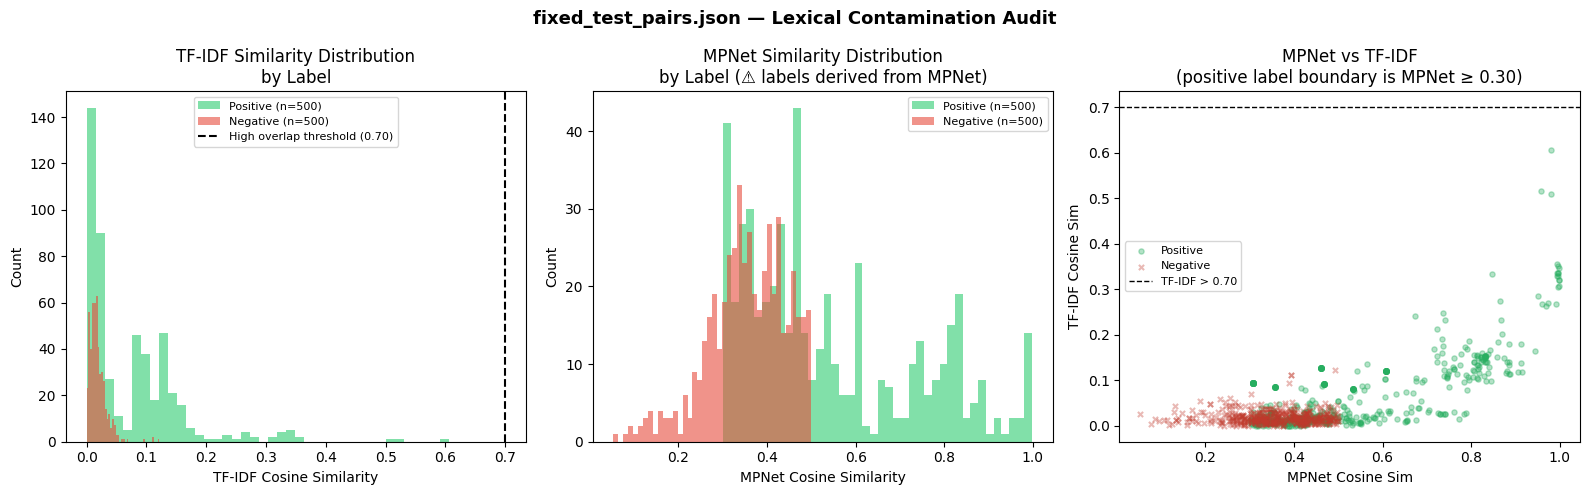

💾 Saved → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v2_results\audit_contamination_20260225_1427.png


In [6]:
# -- Visualise contamination ---------------------------------------------------
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("fixed_test_pairs.json — Lexical Contamination Audit",
             fontsize=13, fontweight="bold")

# 1. TF-IDF similarity distributions by label
ax = axes[0]
for lbl, col, name in [(1, "#2ECC71", "Positive"), (0, "#E74C3C", "Negative")]:
    subset = audit_df[audit_df.label == lbl]["tfidf_sim"]
    ax.hist(subset, bins=40, alpha=0.6, label=f"{name} (n={len(subset)})", color=col)
ax.axvline(0.70, color="black", linestyle="--", linewidth=1.5, label="High overlap threshold (0.70)")
ax.set_xlabel("TF-IDF Cosine Similarity")
ax.set_ylabel("Count")
ax.set_title("TF-IDF Similarity Distribution\nby Label")
ax.legend(fontsize=8)

# 2. MPNet similarity distributions by label
ax = axes[1]
for lbl, col, name in [(1, "#2ECC71", "Positive"), (0, "#E74C3C", "Negative")]:
    subset = audit_df[audit_df.label == lbl]["mpnet_sim"]
    ax.hist(subset, bins=40, alpha=0.6, label=f"{name} (n={len(subset)})", color=col)
ax.set_xlabel("MPNet Cosine Similarity")
ax.set_ylabel("Count")
ax.set_title("MPNet Similarity Distribution\nby Label (⚠️ labels derived from MPNet)")
ax.legend(fontsize=8)

# 3. TF-IDF vs MPNet scatter (coloured by label)
ax = axes[2]
for lbl, col, name, marker in [(1, "#27AE60", "Positive", "o"), (0, "#C0392B", "Negative", "x")]:
    mask = audit_df.label == lbl
    ax.scatter(audit_df[mask]["mpnet_sim"], audit_df[mask]["tfidf_sim"],
               alpha=0.35, s=14, c=col, label=name, marker=marker)
ax.axhline(0.70, color="black", linestyle="--", linewidth=1, label="TF-IDF > 0.70")
ax.set_xlabel("MPNet Cosine Sim")
ax.set_ylabel("TF-IDF Cosine Sim")
ax.set_title("MPNet vs TF-IDF\n(positive label boundary is MPNet ≥ 0.30)")
ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / f"audit_contamination_{TS}.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"💾 Saved → {OUTPUT_DIR / f'audit_contamination_{TS}.png'}")

In [7]:
# -- Examine high-TF-IDF examples to identify boilerplate patterns -------------
high_overlap = audit_df[audit_df["tfidf_high"]].index.tolist()
print(f"📋 {len(high_overlap)} pairs with TF-IDF > 0.70.  Sample (first 3):")
for idx in high_overlap[:3]:
    print(f"\n--- Pair {idx}  |  label={int(gt_labels[idx])}  "
          f"tfidf={tfidf_sims[idx]:.3f}  mpnet={mpnet_sims[idx]:.3f} ---")
    print(f"  text1: {gt_texts1[idx][:300]}")
    print(f"  text2: {gt_texts2[idx][:300]}")

# -- Separability gap analysis -------------------------------------------------
pos_mean = audit_df[audit_df.label == 1]["mpnet_sim"].mean()
neg_mean = audit_df[audit_df.label == 0]["mpnet_sim"].mean()
overlap  = ((audit_df["mpnet_sim"] >= neg_mean) & (audit_df["label"] == 0)).sum() + \
           ((audit_df["mpnet_sim"] <= pos_mean) & (audit_df["label"] == 1)).sum()

print(f"\n📊 Separability (MPNet):")
print(f"   Positive mean : {pos_mean:.4f}")
print(f"   Negative mean : {neg_mean:.4f}")
print(f"   Gap           : {pos_mean - neg_mean:.4f}")
print(f"   Gray-zone overlap: {overlap:,} / {len(audit_df)} pairs  ({overlap/len(audit_df)*100:.1f}%)")

📋 0 pairs with TF-IDF > 0.70.  Sample (first 3):

📊 Separability (MPNet):
   Positive mean : 0.5412
   Negative mean : 0.3547
   Gap           : 0.1865
   Gray-zone overlap: 567 / 1000 pairs  (56.7%)


---
## Step 2 — Build Clean Retrieval Benchmark

**Design**: Leave-one-out retrieval with cross-document query extraction.

- **Corpus**: Full 10,633-row CSV (all ServiceNow incidents)
- **Query**: First non-boilerplate sentence of document A — extracted from document A, but A is **excluded** from the retrieval pool
- **True positive**: The source document A (self-retrieval from the pool) — but since A is excluded, we define the positives as all documents in the same `Service` bucket
- **Why this avoids lexical leakage**: The query sentence shares no exact tokens with the **closest semantic neighbour** (a different document in the same service). TF-IDF can no longer trivially win by string matching the source document.

**Boilerplate stripping**: Remove leading ticket number lines, automated-mail headers, repeated SAP template phrases.

In [8]:
# -- Load full corpus ----------------------------------------------------------
corpus_df = pd.read_csv(
    CSV_PATH,
    usecols=["Number", "Description", "Category", "Priority", "Service"],
    dtype=str,
    low_memory=False,
)
corpus_df = corpus_df.rename(columns={
    "Number": "id", "Description": "text",
    "Category": "category", "Priority": "priority", "Service": "service"
})
corpus_df = corpus_df.dropna(subset=["text"]).drop_duplicates("id").reset_index(drop=True)
corpus_df["service"]  = corpus_df["service"].fillna("unknown")
corpus_df["category"] = corpus_df["category"].fillna("unknown")
corpus_df["priority"] = corpus_df["priority"].fillna("unknown")

print(f"✅ Loaded {len(corpus_df):,} incidents")
print(f"\nService distribution:")
for svc, n in corpus_df["service"].value_counts().items():
    print(f"  {svc[:55]:55s}: {n:5d}  ({n/len(corpus_df)*100:.1f}%)")

✅ Loaded 10,631 incidents

Service distribution:
  Mulesoft/EAI                                           :  4099  (38.6%)
  SAP                                                    :  3109  (29.2%)
  CRM (D365, SalesForce, Genesis, PCube, HussMann Service:  2235  (21.0%)
  eWorkplace (eWorkplace SharePoint & eWorkplace ServiceN:  1042  (9.8%)
  Business Insights (BI)                                 :    73  (0.7%)
  SOA                                                    :    57  (0.5%)
  SAP - BW/SAC                                           :    15  (0.1%)
  Mulesoft/SOA                                           :     1  (0.0%)


In [9]:
# -- Boilerplate stripping ----------------------------------------------------- 
# Patterns identified from corpus exploration:
BOILERPLATE_PATTERNS = [
    r"^(INC|eCU|eTR|RITM|CHG|PRB|TAS)\w+-?\S*\s*",           # ticket number prefixes
    r"note\s*:\s*this is an automated",                         # automated mail header
    r"as advised by (servicenow|sap|the|our)",                  # team escalation boilerplate
    r"please\s+find\s+(below|attached)",                        # template opener
    r"dear\s+(team|all|sir|ma\'am)",                            # salutation
    r"thank(s| you)\s+for",                                     # closing
    r"best\s+regards?",                                         # signature
    r"regards?\.?\s*$",                                         # signature ending
    r"(system|application|system application)\s+error",         # generic error label only
]
_BPLP = [re.compile(p, re.IGNORECASE) for p in BOILERPLATE_PATTERNS]

def strip_boilerplate(text: str) -> str:
    """Remove boilerplate lines and patterns from ITSM ticket text."""
    if not isinstance(text, str):
        return ""
    # Normalise Windows line endings
    text = text.replace("\r\n", "\n").replace("\r", "\n")
    # Drop lines that are boilerplate-heavy
    clean_lines = []
    for line in text.split("\n"):
        line = line.strip()
        if len(line) < 10:
            continue
        if any(p.search(line) for p in _BPLP):
            continue
        clean_lines.append(line)
    cleaned = " ".join(clean_lines).strip()
    # Normalise whitespace
    cleaned = re.sub(r"\s+", " ", cleaned)
    # Strip residual ticket number from the very start of the remaining text
    cleaned = re.sub(r"^(INC|eCU|eTR|RITM)\w+\s+", "", cleaned).strip()
    return cleaned[:512]


def extract_clean_query(text: str, min_words: int = 6, min_chars: int = 30) -> str | None:
    """Extract first meaningful sentence from cleaned text as a query."""
    cleaned = strip_boilerplate(text)
    if not cleaned:
        return None
    sentences = nltk.sent_tokenize(cleaned)
    for sent in sentences:
        words = sent.split()
        if len(words) >= min_words and len(sent) >= min_chars:
            return sent.strip()
    return None


corpus_df["text_clean"] = corpus_df["text"].apply(strip_boilerplate)
corpus_df["query"]      = corpus_df["text"].apply(extract_clean_query)

n_with_query = corpus_df["query"].notna().sum()
print(f"✅ Docs with usable query sentence: {n_with_query:,} / {len(corpus_df):,}")

# Spot-check: query should look different from the full text
sample = corpus_df[corpus_df["query"].notna()].iloc[0]
print(f"\n📝 Sample — raw text (first 200 chars):")
print(f"  {sample['text'][:200]}")
print(f"\n📝 After strip, query extracted:")
print(f"  {sample['query']}")

✅ Docs with usable query sentence: 10,189 / 10,631

📝 Sample — raw text (first 200 chars):
  GRPT not working as expected. ZMMM_PO_REV is not generating correct dates as per maintained in GRPT table. 
E.g. P/O# 100024066
Vendor Ship mode is 03. 
As per GRPT route days are 12 days and GR da

📝 After strip, query extracted:
  ZMMM_PO_REV is not generating correct dates as per maintained in GRPT table.


In [10]:
# -- Build leave-one-out retrieval benchmark -----------------------------------
#
# For each query document Q:
#   - Query  = first clean sentence from Q
#   - Corpus = all documents EXCLUDING Q  (prevents trivial self-retrieval)
#   - Relevant = all docs in the same Service bucket as Q  (metadata label, no encoder)
#
# We sample at most N_QUERIES query documents to keep evaluation fast.
# Requirement: the Service bucket must have ≥ MIN_POOL_SIZE docs so there is
# a meaningful retrieval task (not just k=1 possibilities).

N_QUERIES    = 400
MIN_POOL_SIZE = 50    # Service bucket must have at least this many other docs

# Filter to docs with valid queries and adequate pool
service_counts = corpus_df["service"].value_counts()
eligible_services = service_counts[service_counts >= MIN_POOL_SIZE].index.tolist()
print(f"Eligible services (≥{MIN_POOL_SIZE} docs): {eligible_services}")

eligible_docs = corpus_df[
    corpus_df["query"].notna() &
    corpus_df["service"].isin(eligible_services)
].copy().reset_index(drop=True)

print(f"Eligible query documents: {len(eligible_docs):,}")

# Sample query documents (stratified by service so each service is represented)
query_sample = (
    eligible_docs
    .groupby("service", group_keys=False)
    .apply(lambda g: g.sample(
        min(len(g), max(1, int(N_QUERIES * len(g) / len(eligible_docs)))),
        random_state=SEED
    ))
    .reset_index(drop=True)
)
# Top up to N_QUERIES if under-sampled
if len(query_sample) < N_QUERIES:
    extra = eligible_docs[~eligible_docs["id"].isin(query_sample["id"])].sample(
        min(N_QUERIES - len(query_sample), len(eligible_docs) - len(query_sample)),
        random_state=SEED + 1
    )
    query_sample = pd.concat([query_sample, extra]).head(N_QUERIES).reset_index(drop=True)

print(f"\nQuery sample size: {len(query_sample):,}")
print(f"Service breakdown:\n{query_sample['service'].value_counts().to_string()}")

# Build BEIR-style retrieval structure
# corpus: all docs with valid text (minus each query doc at evaluation time)
corpus_for_eval = corpus_df[corpus_df["text_clean"].str.len() >= 20].copy().reset_index(drop=True)

queries_ret  = {row.id: row.query for row in query_sample.itertuples()}
# qrels: doc Q → all docs in same service (excluding Q itself)
service_to_docs = corpus_for_eval.groupby("service")["id"].apply(list).to_dict()
qrels_ret = {}
for row in query_sample.itertuples():
    relevant = {did: 1 for did in service_to_docs.get(row.service, [])
                if did != row.id}
    if relevant:
        qrels_ret[row.id] = relevant

queries_ret = {qid: q for qid, q in queries_ret.items() if qid in qrels_ret}
print(f"\n✅ Clean retrieval benchmark:")
print(f"   Queries     : {len(queries_ret):,}")
print(f"   Corpus docs : {len(corpus_for_eval):,}")
print(f"   Avg relevant per query: {np.mean([len(v) for v in qrels_ret.values()]):.0f}")

Eligible services (≥50 docs): ['Mulesoft/EAI', 'SAP', 'CRM (D365, SalesForce, Genesis, PCube, HussMann Services)', 'eWorkplace (eWorkplace SharePoint & eWorkplace ServiceNow)', 'Business Insights (BI)', 'SOA']
Eligible query documents: 10,174

Query sample size: 400
Service breakdown:
service
Mulesoft/EAI                                                  161
SAP                                                           115
CRM (D365, SalesForce, Genesis, PCube, HussMann Services)      83
eWorkplace (eWorkplace SharePoint & eWorkplace ServiceNow)     38
Business Insights (BI)                                          2
SOA                                                             1

✅ Clean retrieval benchmark:
   Queries     : 400
   Corpus docs : 10,492
   Avg relevant per query: 3076


In [11]:
# -- Retrieval evaluation function (with TF-IDF support) -----------------------

def evaluate_retrieval(
    model,                 # SentenceTransformer OR None (→ TF-IDF)
    corpus_df_eval,        # pd.DataFrame with columns id, text_clean
    queries: dict,         # {qid: query_text}
    qrels: dict,           # {qid: {did: 1}}
    top_k: list = None,
    batch_size: int = 64,
    query_chunk: int = 32, # evaluate this many queries at a time to cap RAM
    tfidf_model=None,      # pre-fitted TfidfVectorizer for TF-IDF mode
) -> dict:
    """Compute NDCG@10, MRR@10, Recall@{1,5,10}.

    Embeddings are stored as CPU numpy arrays; similarity is computed in
    query-batches of `query_chunk` rows so the GPU similarity matrix stays
    small (query_chunk × n_docs) instead of (n_queries × n_docs).
    Leave-one-out: each query's source doc is excluded by setting its score
    to -inf before ranking.
    """
    if top_k is None:
        top_k = [1, 5, 10]

    doc_ids   = list(corpus_df_eval["id"])
    doc_texts = list(corpus_df_eval["text_clean"])
    qids      = list(queries.keys())
    qtexts    = [queries[q] for q in qids]

    # --- Encode ---------------------------------------------------------------
    if model is not None:
        print(f"    Encoding {len(doc_texts):,} corpus docs …", end=" ", flush=True)
        doc_embs = model.encode(
            doc_texts, batch_size=batch_size, convert_to_numpy=True,
            normalize_embeddings=True, show_progress_bar=False
        )  # (n_docs, D)  — CPU numpy
        print("done")

        print(f"    Encoding {len(qtexts):,} queries …", end=" ", flush=True)
        q_embs = model.encode(
            qtexts, batch_size=batch_size, convert_to_numpy=True,
            normalize_embeddings=True, show_progress_bar=False
        )  # (n_queries, D)  — CPU numpy
        print("done")

        use_tfidf = False
    else:
        assert tfidf_model is not None, "Pass tfidf_model when model=None"
        doc_embs = tfidf_model.transform(doc_texts)   # sparse (n_docs, V)
        q_embs   = tfidf_model.transform(qtexts)      # sparse (n_queries, V)
        use_tfidf = True

    id_to_col = {did: ci for ci, did in enumerate(doc_ids)}

    ndcg_vals, mrr_vals = [], []
    recall = {k: [] for k in top_k}

    # --- Score in query-chunks to avoid OOM -----------------------------------
    for chunk_start in range(0, len(qids), query_chunk):
        chunk_end   = min(chunk_start + query_chunk, len(qids))
        chunk_qids  = qids[chunk_start:chunk_end]

        if use_tfidf:
            chunk_sims = sk_cosine(
                q_embs[chunk_start:chunk_end], doc_embs
            )  # (chunk, n_docs)  — dense numpy
        else:
            # dot product of normalised vectors == cosine similarity
            chunk_sims = q_embs[chunk_start:chunk_end] @ doc_embs.T  # (chunk, n_docs)

        for qi_local, qid in enumerate(chunk_qids):
            relevant = set(qrels.get(qid, {}).keys())
            if not relevant:
                continue

            row_sims = chunk_sims[qi_local].copy()

            # Leave-one-out: exclude query doc from its own retrieval
            if qid in id_to_col:
                row_sims[id_to_col[qid]] = -np.inf

            ranked = np.argsort(-row_sims)

            # NDCG@10
            dcg  = sum(1/np.log2(r+2) for r, idx in enumerate(ranked[:10])
                       if doc_ids[idx] in relevant)
            idcg = sum(1/np.log2(r+2) for r in range(min(len(relevant), 10)))
            ndcg_vals.append(dcg / idcg if idcg > 0 else 0.0)

            # MRR@10
            mrr = next((1/(r+1) for r, idx in enumerate(ranked[:10])
                        if doc_ids[idx] in relevant), 0.0)
            mrr_vals.append(mrr)

            # Recall@k
            for k in top_k:
                hits = sum(1 for idx in ranked[:k] if doc_ids[idx] in relevant)
                recall[k].append(min(1.0, hits / len(relevant)))

    metrics = {
        "NDCG@10": float(np.mean(ndcg_vals)),
        "MRR@10":  float(np.mean(mrr_vals)),
    }
    for k in top_k:
        metrics[f"Recall@{k}"] = float(np.mean(recall[k]))
    return metrics

print("✅ Retrieval evaluator defined (chunked CPU dot-product, no OOM)")

✅ Retrieval evaluator defined (chunked CPU dot-product, no OOM)


---
## Step 3 — Build `semantic_test_pairs_v2.json` (Metadata-Based Labels)

**Why**: `fixed_test_pairs.json` uses `all-mpnet-base-v2` cosine ≥ 0.30 as the positive label — creating a **circular benchmark** where models sharing the same base encoder are evaluated against their own prior beliefs.

**New labeling strategy** (no encoder involved):
- **Positive**: Same `Service` AND same `Category`. Documents sharing both are genuinely related ITSM cases.
- **Negative**: Different `Service`. Documents from different service lines (SAP vs Mulesoft vs CRM) address fundamentally different problems.
- **Confidence gate**: A pair is only included if its TF-IDF cosine similarity is **below 0.5** for positives (no trivial lexical overlap) and **below 0.3** for negatives (no accidental similarity). This ensures the benchmark tests semantic matching, not keyword matching.

In [12]:
# -- Build semantic_test_pairs_v2.json -----------------------------------------
TARGET_POS  = 500
TARGET_NEG  = 500
MAX_TFIDF_POS = 0.50   # positives must not be trivially lexically similar
MAX_TFIDF_NEG = 0.30   # negatives must not have moderate lexical overlap

# Use only docs with clean text
pair_pool = corpus_df[corpus_df["text_clean"].str.len() >= 40].copy().reset_index(drop=True)
print(f"Pair pool size: {len(pair_pool):,}")

# Fit TF-IDF on pool for the confidence gate
tfidf_pool = TfidfVectorizer(max_features=30_000, ngram_range=(1, 2), strip_accents="unicode")
tfidf_pool.fit(pair_pool["text_clean"].tolist())
pool_embs = tfidf_pool.transform(pair_pool["text_clean"].tolist())
print("✅ TF-IDF fitted on pool")

# Group by (service, category) for positive pair candidates
# and by service for negative pair candidates
service_cat_groups = pair_pool.groupby(["service", "category"]).groups  # {(svc,cat): [idx...]}
service_groups     = pair_pool.groupby("service").groups               # {svc: [idx...]}
services_list      = list(service_groups.keys())

rng = np.random.default_rng(SEED)

pos_pairs, neg_pairs = [], []

# --- POSITIVE PAIRS: same service + same category ----------------------------
same_svc_cat_groups = [(k, v) for k, v in service_cat_groups.items() if len(v) >= 2]
rng.shuffle(same_svc_cat_groups)
attempts = 0
for (svc, cat), idxs in same_svc_cat_groups:
    if len(pos_pairs) >= TARGET_POS:
        break
    idxs = list(idxs)
    rng.shuffle(idxs)
    for i in range(0, len(idxs) - 1, 2):
        if len(pos_pairs) >= TARGET_POS:
            break
        a, b = idxs[i], idxs[i + 1]
        tfidf_cos = float(sk_cosine(pool_embs[a], pool_embs[b])[0, 0])
        attempts += 1
        if tfidf_cos <= MAX_TFIDF_POS:
            pos_pairs.append({
                "text1":    pair_pool.iloc[a]["text_clean"],
                "text2":    pair_pool.iloc[b]["text_clean"],
                "label":    1,
                "service":  svc,
                "category": cat,
                "tfidf_sim": round(tfidf_cos, 4),
            })
print(f"✅ Positive pairs built: {len(pos_pairs):,}  (from {attempts:,} attempts, gate ≤{MAX_TFIDF_POS})")

# --- NEGATIVE PAIRS: different service ----------------------------------------
neg_attempts = 0
max_neg_attempts = TARGET_NEG * 25
while len(neg_pairs) < TARGET_NEG and neg_attempts < max_neg_attempts:
    svc_a, svc_b = rng.choice(services_list, 2, replace=False)
    pool_a = list(service_groups[svc_a])
    pool_b = list(service_groups[svc_b])
    if not pool_a or not pool_b:
        continue
    a = rng.choice(pool_a)
    b = rng.choice(pool_b)
    tfidf_cos = float(sk_cosine(pool_embs[a], pool_embs[b])[0, 0])
    neg_attempts += 1
    if tfidf_cos <= MAX_TFIDF_NEG:
        neg_pairs.append({
            "text1":     pair_pool.iloc[a]["text_clean"],
            "text2":     pair_pool.iloc[b]["text_clean"],
            "label":     0,
            "service_a": svc_a,
            "service_b": svc_b,
            "tfidf_sim": round(tfidf_cos, 4),
        })

print(f"✅ Negative pairs built: {len(neg_pairs):,}  (from {neg_attempts:,} attempts, gate ≤{MAX_TFIDF_NEG})")

Pair pool size: 10,154
✅ TF-IDF fitted on pool
✅ Positive pairs built: 500  (from 520 attempts, gate ≤0.5)
✅ Negative pairs built: 500  (from 500 attempts, gate ≤0.3)


In [13]:
# -- Assemble and save semantic_test_pairs_v2.json -----------------------------
all_pairs_v2 = pos_pairs + neg_pairs
random.shuffle(all_pairs_v2)

v2_texts1  = [p["text1"] for p in all_pairs_v2]
v2_texts2  = [p["text2"] for p in all_pairs_v2]
v2_labels  = [p["label"] for p in all_pairs_v2]
v2_tfidf   = [p["tfidf_sim"] for p in all_pairs_v2]

v2_dataset = {
    "texts1":   v2_texts1,
    "texts2":   v2_texts2,
    "labels":   v2_labels,
    "tfidf_sims": v2_tfidf,
    "metadata": {
        "created_at":      datetime.now().isoformat(),
        "total_pairs":     len(all_pairs_v2),
        "num_positive":    len(pos_pairs),
        "num_negative":    len(neg_pairs),
        "labeling":        "metadata (Service+Category=positive, DiffService=negative)",
        "tfidf_gate_pos":  MAX_TFIDF_POS,
        "tfidf_gate_neg":  MAX_TFIDF_NEG,
        "no_encoder_used": True,
        "source_csv":      str(CSV_PATH),
    }
}

with open(NEW_PAIRS_PATH, "w", encoding="utf-8") as f:
    json.dump(v2_dataset, f, indent=2, ensure_ascii=False)
print(f"💾 Saved → {NEW_PAIRS_PATH}")
print(f"   Total pairs : {len(all_pairs_v2):,}")
print(f"   Positives   : {sum(v2_labels):,}")
print(f"   Negatives   : {len(v2_labels)-sum(v2_labels):,}")
print(f"   TF-IDF stats (positives):  mean={np.mean([p['tfidf_sim'] for p in pos_pairs]):.3f}")
print(f"   TF-IDF stats (negatives):  mean={np.mean([p['tfidf_sim'] for p in neg_pairs]):.3f}")

💾 Saved → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\data_new\semantic_test_pairs_v2.json
   Total pairs : 1,000
   Positives   : 500
   Negatives   : 500
   TF-IDF stats (positives):  mean=0.150
   TF-IDF stats (negatives):  mean=0.011


---
## Step 4 — Fix Threshold Selection (80/20 Val/Test Split)

**Problem**: `evaluate_model_v2.ipynb` runs `find_optimal_threshold` on all 1,000 pairs and **also reports F1/accuracy on those same 1,000 pairs** — the threshold is in-sample selected, inflating F1.

**Fix**: Split `fixed_test_pairs.json` 800 test / 200 val. Select threshold on val; report F1 on the held-out 800.

In [14]:
# -- 80/20 split of fixed_test_pairs.json for threshold selection --------------
all_indices = list(range(len(gt_labels)))
test_idx, val_idx = train_test_split(
    all_indices, test_size=0.20, random_state=SEED,
    stratify=gt_labels.astype(int)
)

def threshold_metrics(sims, labels, threshold):
    preds = (sims >= threshold).astype(int)
    return {
        "f1":        float(f1_score(labels, preds, zero_division=0)),
        "precision": float(precision_score(labels, preds, zero_division=0)),
        "recall":    float(recall_score(labels, preds, zero_division=0)),
        "accuracy":  float((preds == labels).mean()),
    }

def find_optimal_threshold(sims, labels, n_points=200):
    """Grid-search threshold on validation set only."""
    thresholds = np.linspace(sims.min(), sims.max(), n_points)
    best_thr, best_f1 = 0.5, 0.0
    for thr in thresholds:
        f1 = f1_score(labels, (sims >= thr).astype(int), zero_division=0)
        if f1 > best_f1:
            best_f1, best_thr = f1, float(thr)
    return best_thr, best_f1

print(f"✅ Split: {len(test_idx)} test | {len(val_idx)} val")

# --- Evaluate models on the fixed_test_pairs with corrected protocol ----------
# We'll load models incrementally, encode, measure Spearman & threshold-fixed F1
GT_RESULTS_V2 = {}

def eval_pairs(model, t1, t2, labels, val_idx, test_idx, name="",
               tfidf_model=None):
    """Encode pairs, compute Spearman/ROC-AUC/F1 with correct threshold."""
    labels = np.array(labels, dtype=float)
    if model is not None:
        e1 = model.encode(t1, batch_size=64, convert_to_numpy=True,
                          normalize_embeddings=True, show_progress_bar=False)
        e2 = model.encode(t2, batch_size=64, convert_to_numpy=True,
                          normalize_embeddings=True, show_progress_bar=False)
        sims = np.sum(e1 * e2, axis=1)
    else:
        assert tfidf_model is not None
        em1 = tfidf_model.transform(t1)
        em2 = tfidf_model.transform(t2)
        sims = np.array([float(sk_cosine(em1[i], em2[i])[0, 0])
                         for i in range(len(labels))])

    # Threshold selected on validation set
    val_sims   = sims[val_idx]
    val_labels = labels[val_idx]
    best_thr, val_f1 = find_optimal_threshold(val_sims, val_labels)

    # Report on held-out test set
    test_sims   = sims[test_idx]
    test_labels = labels[test_idx]
    test_m      = threshold_metrics(test_sims, test_labels, best_thr)

    # Threshold-free metrics on full set
    sp,  _ = spearmanr(sims, labels)
    auc    = roc_auc_score(labels, sims)

    result = {
        "Spearman":       round(float(sp),  4),
        "ROC_AUC":        round(float(auc), 4),
        "F1_test":        round(test_m["f1"],        4),
        "Precision_test": round(test_m["precision"], 4),
        "Recall_test":    round(test_m["recall"],    4),
        "Accuracy_test":  round(test_m["accuracy"],  4),
        "Threshold":      round(best_thr, 4),
        "Val_F1":         round(val_f1, 4),
    }
    if name:
        print(f"  {name:30s}  Spearman={sp:.4f}  ROC-AUC={auc:.4f}  "
              f"F1(test)={test_m['f1']:.4f}  thr={best_thr:.3f}")
    return result, sims

print("\n✅ eval_pairs() helper defined — ready to evaluate models")

✅ Split: 800 test | 200 val

✅ eval_pairs() helper defined — ready to evaluate models


---
## Step 5 — Evaluate All Models on Both Benchmarks

We evaluate every model on:
1. **OLD benchmark** — `fixed_test_pairs.json` (pair-level, corrected threshold selection)
2. **NEW pair benchmark** — `semantic_test_pairs_v2.json` (metadata labels, no encoder circularity)
3. **NEW retrieval benchmark** — leave-one-out retrieval (cross-document queries, no lexical leakage)

In [15]:
# -- Fit TF-IDF for retrieval and pair baselines -------------------------------
tfidf_all = TfidfVectorizer(max_features=30_000, ngram_range=(1, 2), strip_accents="unicode")
tfidf_all.fit(corpus_for_eval["text_clean"].tolist())
print("✅ TF-IDF fitted on eval corpus for retrieval")

# Fit a separate one on the GT pair texts for pair-level eval
tfidf_gt = TfidfVectorizer(max_features=30_000, ngram_range=(1, 2), strip_accents="unicode")
tfidf_gt.fit(gt_texts1 + gt_texts2)
print("✅ TF-IDF fitted on GT pair texts")

✅ TF-IDF fitted on eval corpus for retrieval
✅ TF-IDF fitted on GT pair texts


In [16]:
# -- TF-IDF Baseline -----------------------------------------------------------
ALL_RETRIEVAL_RESULTS = {}
ALL_PAIR_RESULTS_OLD  = {}

print("=" * 65)
print("  TF-IDF / BM25 approximation")
print("=" * 65)

ret_m = evaluate_retrieval(None, corpus_for_eval, queries_ret, qrels_ret,
                           tfidf_model=tfidf_all)
ALL_RETRIEVAL_RESULTS["TF-IDF_BM25"] = ret_m
print("  Retrieval metrics (CLEAN benchmark):")
for k, v in ret_m.items(): print(f"    {k:12s}: {v:.4f}")

pair_m, _ = eval_pairs(None, gt_texts1, gt_texts2, gt_labels,
                        val_idx, test_idx, name="TF-IDF_BM25 (OLD pairs)",
                        tfidf_model=tfidf_gt)
ALL_PAIR_RESULTS_OLD["TF-IDF_BM25"] = pair_m

  TF-IDF / BM25 approximation
  Retrieval metrics (CLEAN benchmark):
    NDCG@10     : 0.8113
    MRR@10      : 0.9082
    Recall@1    : 0.0004
    Recall@5    : 0.0016
    Recall@10   : 0.0031
  TF-IDF_BM25 (OLD pairs)         Spearman=0.3614  ROC-AUC=0.7086  F1(test)=0.6288  thr=0.026


In [17]:
# -- Base MPNet (vanilla) ------------------------------------------------------
print("=" * 65)
print("  Base MPNet (all-mpnet-base-v2, no fine-tuning)")
print("=" * 65)

_m = SentenceTransformer(BASE_MODEL, device=DEVICE)

ret_m = evaluate_retrieval(_m, corpus_for_eval, queries_ret, qrels_ret)
ALL_RETRIEVAL_RESULTS["Base_MPNet"] = ret_m
print("  Retrieval metrics (CLEAN benchmark):")
for k, v in ret_m.items(): print(f"    {k:12s}: {v:.4f}")

pair_m, _ = eval_pairs(_m, gt_texts1, gt_texts2, gt_labels,
                        val_idx, test_idx, name="Base MPNet (OLD pairs)")
ALL_PAIR_RESULTS_OLD["Base_MPNet"] = pair_m

del _m
torch.cuda.empty_cache() if DEVICE == "cuda" else None

  Base MPNet (all-mpnet-base-v2, no fine-tuning)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


    Encoding 10,492 corpus docs … done
    Encoding 400 queries … done
  Retrieval metrics (CLEAN benchmark):
    NDCG@10     : 0.8308
    MRR@10      : 0.9210
    Recall@1    : 0.0004
    Recall@5    : 0.0017
    Recall@10   : 0.0033
  Base MPNet (OLD pairs)          Spearman=0.5038  ROC-AUC=0.7909  F1(test)=0.7109  thr=0.341


In [18]:
# -- V4 Cosine (PEFT adapter) --------------------------------------------------
print("=" * 65)
print("  V4 Cosine (MPNet + LoRA r=16 adapter)")
print("=" * 65)

if V4_MODEL_PATH.exists():
    try:
        from peft import PeftModel
        _m = SentenceTransformer(BASE_MODEL, device=DEVICE)
        _m[0].auto_model = PeftModel.from_pretrained(_m[0].auto_model, str(V4_MODEL_PATH))
        print("  ✅ PEFT LoRA adapter injected")

        ret_m = evaluate_retrieval(_m, corpus_for_eval, queries_ret, qrels_ret)
        ALL_RETRIEVAL_RESULTS["V4_Cosine"] = ret_m
        print("  Retrieval metrics (CLEAN benchmark):")
        for k, v in ret_m.items(): print(f"    {k:12s}: {v:.4f}")

        pair_m, _ = eval_pairs(_m, gt_texts1, gt_texts2, gt_labels,
                                val_idx, test_idx, name="V4 Cosine (OLD pairs)")
        ALL_PAIR_RESULTS_OLD["V4_Cosine"] = pair_m

        del _m
        torch.cuda.empty_cache() if DEVICE == "cuda" else None
    except Exception as e:
        print(f"⚠️  Failed to load V4 model: {e}")
else:
    print(f"⚠️  V4 model path not found: {V4_MODEL_PATH}")

  V4 Cosine (MPNet + LoRA r=16 adapter)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  ✅ PEFT LoRA adapter injected
    Encoding 10,492 corpus docs … done
    Encoding 400 queries … done
  Retrieval metrics (CLEAN benchmark):
    NDCG@10     : 0.8156
    MRR@10      : 0.9037
    Recall@1    : 0.0004
    Recall@5    : 0.0017
    Recall@10   : 0.0032
  V4 Cosine (OLD pairs)           Spearman=0.4949  ROC-AUC=0.7857  F1(test)=0.7135  thr=0.386


In [19]:
# -- ICT (unsupervised) --------------------------------------------------------
print("=" * 65)
print("  ICT (Inverse Cloze Task, 6 epochs)")
print("=" * 65)

if ICT_PATH.exists():
    _m = SentenceTransformer(str(ICT_PATH), device=DEVICE)

    ret_m = evaluate_retrieval(_m, corpus_for_eval, queries_ret, qrels_ret)
    ALL_RETRIEVAL_RESULTS["ICT"] = ret_m
    print("  Retrieval metrics (CLEAN benchmark):")
    for k, v in ret_m.items(): print(f"    {k:12s}: {v:.4f}")

    pair_m, _ = eval_pairs(_m, gt_texts1, gt_texts2, gt_labels,
                            val_idx, test_idx, name="ICT (OLD pairs)")
    ALL_PAIR_RESULTS_OLD["ICT"] = pair_m

    del _m
    torch.cuda.empty_cache() if DEVICE == "cuda" else None
else:
    print(f"⚠️  ICT model not found at {ICT_PATH}")

  ICT (Inverse Cloze Task, 6 epochs)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

    Encoding 10,492 corpus docs … done
    Encoding 400 queries … done
  Retrieval metrics (CLEAN benchmark):
    NDCG@10     : 0.8437
    MRR@10      : 0.9080
    Recall@1    : 0.0004
    Recall@5    : 0.0017
    Recall@10   : 0.0033
  ICT (OLD pairs)                 Spearman=0.3569  ROC-AUC=0.7060  F1(test)=0.6320  thr=0.110


In [20]:
# -- TSDAE (unsupervised) ------------------------------------------------------
print("=" * 65)
print("  TSDAE (Denoising Autoencoder, 1 epoch, BERT)")
print("=" * 65)

if TSDAE_PATH.exists():
    _m = SentenceTransformer(str(TSDAE_PATH), device=DEVICE)

    ret_m = evaluate_retrieval(_m, corpus_for_eval, queries_ret, qrels_ret)
    ALL_RETRIEVAL_RESULTS["TSDAE"] = ret_m
    print("  Retrieval metrics (CLEAN benchmark):")
    for k, v in ret_m.items(): print(f"    {k:12s}: {v:.4f}")

    pair_m, _ = eval_pairs(_m, gt_texts1, gt_texts2, gt_labels,
                            val_idx, test_idx, name="TSDAE (OLD pairs)")
    ALL_PAIR_RESULTS_OLD["TSDAE"] = pair_m

    del _m
    torch.cuda.empty_cache() if DEVICE == "cuda" else None
else:
    print(f"⚠️  TSDAE model not found at {TSDAE_PATH}")

  TSDAE (Denoising Autoencoder, 1 epoch, BERT)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

    Encoding 10,492 corpus docs … done
    Encoding 400 queries … done
  Retrieval metrics (CLEAN benchmark):
    NDCG@10     : 0.5375
    MRR@10      : 0.6563
    Recall@1    : 0.0002
    Recall@5    : 0.0011
    Recall@10   : 0.0021
  TSDAE (OLD pairs)               Spearman=0.3316  ROC-AUC=0.6914  F1(test)=0.6797  thr=0.899


In [21]:
# -- GPL (unsupervised) --------------------------------------------------------
print("=" * 65)
print("  GPL (Generative Pseudo Labels, 1 epoch, MarginMSE)")
print("=" * 65)

if GPL_PATH.exists():
    _m = SentenceTransformer(str(GPL_PATH), device=DEVICE)

    ret_m = evaluate_retrieval(_m, corpus_for_eval, queries_ret, qrels_ret)
    ALL_RETRIEVAL_RESULTS["GPL"] = ret_m
    print("  Retrieval metrics (CLEAN benchmark):")
    for k, v in ret_m.items(): print(f"    {k:12s}: {v:.4f}")

    pair_m, _ = eval_pairs(_m, gt_texts1, gt_texts2, gt_labels,
                            val_idx, test_idx, name="GPL (OLD pairs)")
    ALL_PAIR_RESULTS_OLD["GPL"] = pair_m

    del _m
    torch.cuda.empty_cache() if DEVICE == "cuda" else None
else:
    print(f"⚠️  GPL model not found at {GPL_PATH}")

  GPL (Generative Pseudo Labels, 1 epoch, MarginMSE)


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

    Encoding 10,492 corpus docs … done
    Encoding 400 queries … done
  Retrieval metrics (CLEAN benchmark):
    NDCG@10     : 0.5283
    MRR@10      : 0.6609
    Recall@1    : 0.0003
    Recall@5    : 0.0011
    Recall@10   : 0.0020
  GPL (OLD pairs)                 Spearman=0.1222  ROC-AUC=0.5705  F1(test)=0.6656  thr=-0.998


In [22]:
# -- Evaluate all models on semantic_test_pairs_v2.json ------------------------
ALL_PAIR_RESULTS_NEW = {}
v2_labels_arr = np.array(v2_labels, dtype=float)
v2_test_idx, v2_val_idx = train_test_split(
    list(range(len(v2_labels))), test_size=0.20, random_state=SEED,
    stratify=v2_labels_arr.astype(int)
)

print("\n" + "=" * 65)
print("  Evaluating on NEW semantic_test_pairs_v2.json")
print("=" * 65)

# TF-IDF on V2 pairs
tfidf_v2 = TfidfVectorizer(max_features=30_000, ngram_range=(1, 2), strip_accents="unicode")
tfidf_v2.fit(v2_texts1 + v2_texts2)
pair_m, _ = eval_pairs(None, v2_texts1, v2_texts2, v2_labels_arr,
                        v2_val_idx, v2_test_idx, name="TF-IDF (NEW pairs)",
                        tfidf_model=tfidf_v2)
ALL_PAIR_RESULTS_NEW["TF-IDF_BM25"] = pair_m

# All neural models on v2 pairs
model_configs = [
    ("Base_MPNet",  BASE_MODEL,    None),
    ("ICT",         str(ICT_PATH), None),
    ("TSDAE",       str(TSDAE_PATH), None),
    ("GPL",         str(GPL_PATH), None),
]

for mname, mpath, _ in model_configs:
    p = Path(mpath) if not mpath.startswith("sentence") else None
    if p is not None and not p.exists():
        print(f"  ⚠️  {mname}: path not found, skipping")
        continue
    _m = SentenceTransformer(mpath, device=DEVICE)
    pair_m, _ = eval_pairs(_m, v2_texts1, v2_texts2, v2_labels_arr,
                            v2_val_idx, v2_test_idx, name=f"{mname} (NEW pairs)")
    ALL_PAIR_RESULTS_NEW[mname] = pair_m
    del _m
    torch.cuda.empty_cache() if DEVICE == "cuda" else None

# V4 Cosine on v2 pairs
if V4_MODEL_PATH.exists():
    try:
        from peft import PeftModel
        _m = SentenceTransformer(BASE_MODEL, device=DEVICE)
        _m[0].auto_model = PeftModel.from_pretrained(_m[0].auto_model, str(V4_MODEL_PATH))
        pair_m, _ = eval_pairs(_m, v2_texts1, v2_texts2, v2_labels_arr,
                                v2_val_idx, v2_test_idx, name="V4_Cosine (NEW pairs)")
        ALL_PAIR_RESULTS_NEW["V4_Cosine"] = pair_m
        del _m
        torch.cuda.empty_cache() if DEVICE == "cuda" else None
    except Exception as e:
        print(f"  ⚠️  V4 PEFT failed: {e}")


  Evaluating on NEW semantic_test_pairs_v2.json
  TF-IDF (NEW pairs)              Spearman=0.8051  ROC-AUC=0.9641  F1(test)=0.9365  thr=0.042


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  Base_MPNet (NEW pairs)          Spearman=0.8333  ROC-AUC=0.9811  F1(test)=0.9514  thr=0.495


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

  ICT (NEW pairs)                 Spearman=0.7972  ROC-AUC=0.9603  F1(test)=0.9169  thr=0.174


... (3 outputs left out)

  GPL (NEW pairs)                 Spearman=0.4064  ROC-AUC=0.7346  F1(test)=0.6983  thr=0.990


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


  V4_Cosine (NEW pairs)           Spearman=0.8382  ROC-AUC=0.9839  F1(test)=0.9495  thr=0.656


---
## Step 6 — Side-by-Side Comparison: Old vs New Benchmarks

In [23]:
# -- Full comparison tables ----------------------------------------------------
print("=" * 65)
print("  RETRIEVAL — Clean Benchmark (Leave-One-Out, Cross-Document Queries)")
print("=" * 65)
ret_df = pd.DataFrame(ALL_RETRIEVAL_RESULTS).T.sort_values("NDCG@10", ascending=False)
print(ret_df.round(4).to_string())
print()

print("=" * 65)
print("  PAIR-LEVEL — OLD fixed_test_pairs.json (corrected threshold)")
print("=" * 65)
old_df = pd.DataFrame(ALL_PAIR_RESULTS_OLD).T[["Spearman","ROC_AUC","F1_test","Accuracy_test","Threshold"]]
old_df = old_df.sort_values("Spearman", ascending=False)
print(old_df.round(4).to_string())
print("  ⚠️  Note: MPNet-based circular labels — use NEW benchmark as primary.")
print()

print("=" * 65)
print("  PAIR-LEVEL — NEW semantic_test_pairs_v2.json (metadata labels)")
print("=" * 65)
new_df = pd.DataFrame(ALL_PAIR_RESULTS_NEW).T[["Spearman","ROC_AUC","F1_test","Accuracy_test","Threshold"]]
new_df = new_df.sort_values("Spearman", ascending=False)
print(new_df.round(4).to_string())
print()

  RETRIEVAL — Clean Benchmark (Leave-One-Out, Cross-Document Queries)
             NDCG@10  MRR@10  Recall@1  Recall@5  Recall@10
ICT           0.8437  0.9080    0.0004    0.0017     0.0033
Base_MPNet    0.8308  0.9210    0.0004    0.0017     0.0033
V4_Cosine     0.8156  0.9037    0.0004    0.0017     0.0032
TF-IDF_BM25   0.8113  0.9082    0.0004    0.0016     0.0031
TSDAE         0.5375  0.6563    0.0002    0.0011     0.0021
GPL           0.5283  0.6609    0.0003    0.0011     0.0020

  PAIR-LEVEL — OLD fixed_test_pairs.json (corrected threshold)
             Spearman  ROC_AUC  F1_test  Accuracy_test  Threshold
Base_MPNet     0.5038   0.7909   0.7109         0.6462     0.3407
V4_Cosine      0.4949   0.7857   0.7135         0.6737     0.3862
TF-IDF_BM25    0.3614   0.7086   0.6288         0.6650     0.0259
ICT            0.3569   0.7060   0.6320         0.6462     0.1103
TSDAE          0.3316   0.6914   0.6797         0.6300     0.8985
GPL            0.1222   0.5705   0.6656         0.

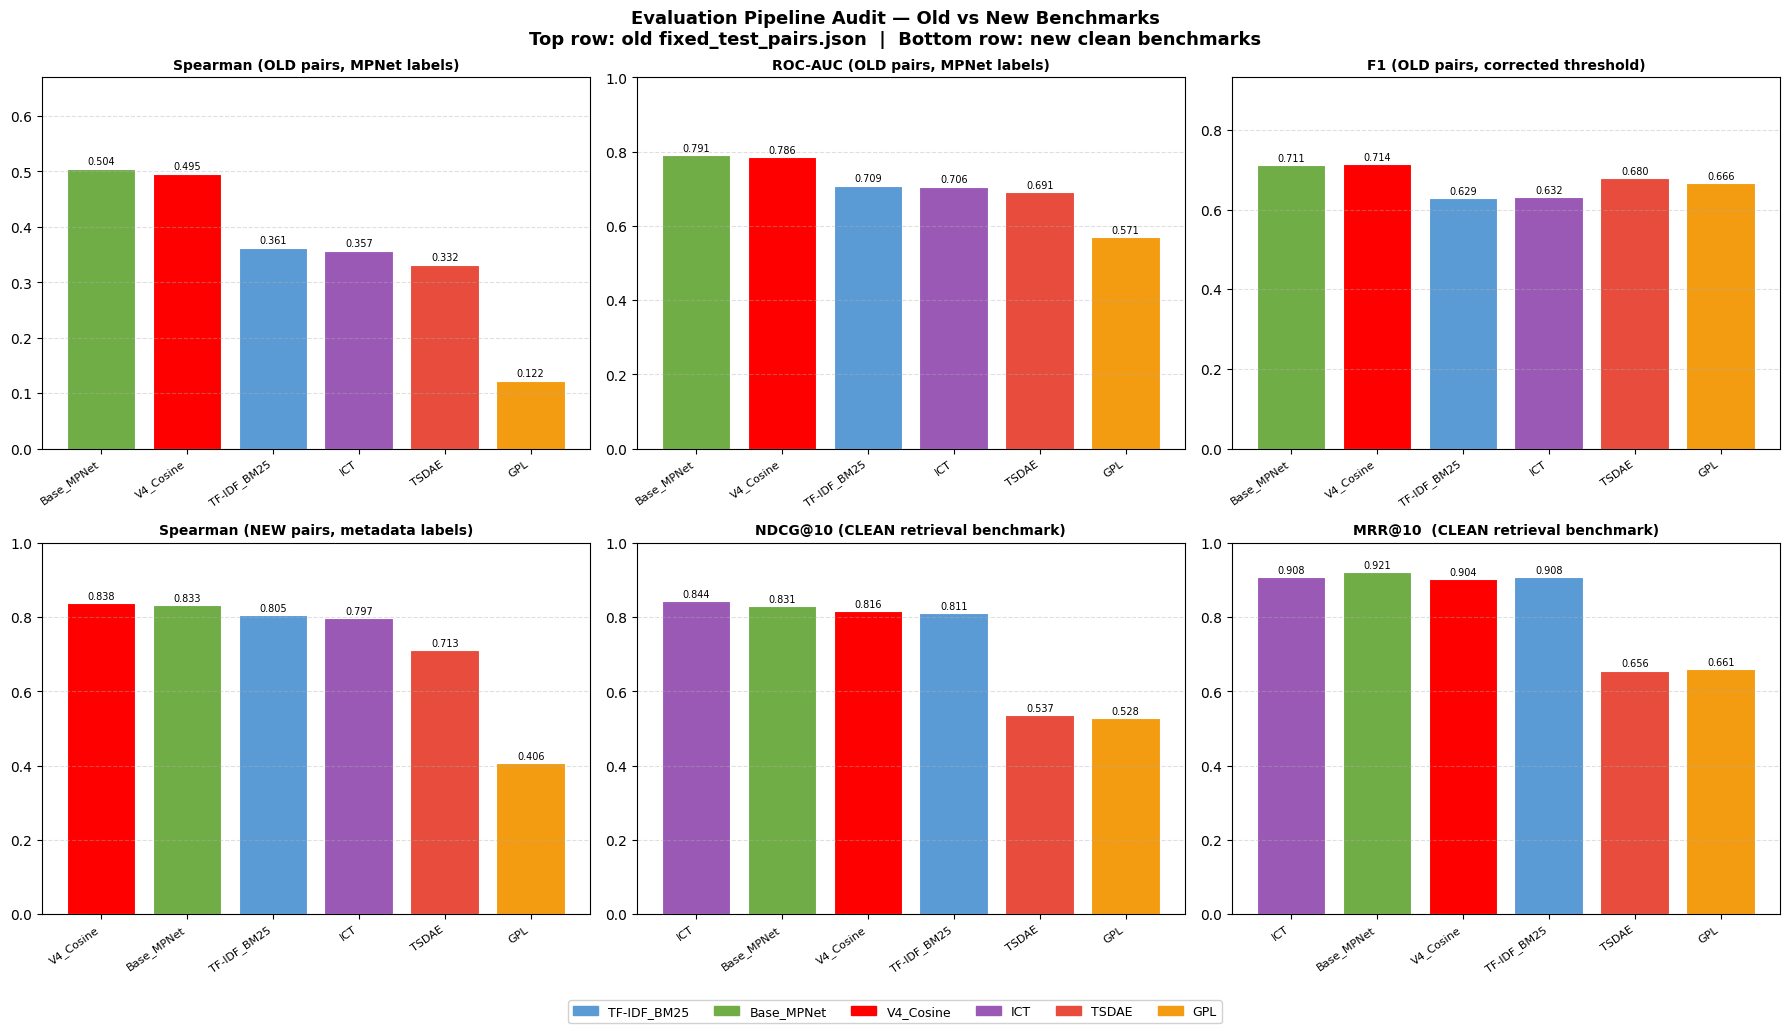

💾 Saved → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v2_results\comparison_old_vs_new_20260225_1427.png


In [24]:
# -- Comparison bar charts: Old vs New benchmarks ------------------------------
palette = {
    "TF-IDF_BM25": "#5B9BD5",
    "Base_MPNet":  "#70AD47",
    "V4_Cosine":   "#FF0000",
    "ICT":         "#9B59B6",
    "TSDAE":       "#E74C3C",
    "GPL":         "#F39C12",
}

def bar_compare(ax, df, metric, title, palette):
    models = list(df.index)
    vals   = [float(df.loc[m, metric]) if metric in df.columns else 0.0 for m in models]
    cols   = [palette.get(m, "#95A5A6") for m in models]
    bars   = ax.bar(range(len(models)), vals, color=cols, edgecolor="white", linewidth=0.8)
    ax.set_title(title, fontsize=10, fontweight="bold")
    ax.set_xticks(range(len(models)))
    ax.set_xticklabels(models, rotation=35, ha="right", fontsize=8)
    ax.set_ylim(0, min(1.0, max(vals) * 1.25 + 0.04))
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
                f"{v:.3f}", ha="center", va="bottom", fontsize=7)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle(
    "Evaluation Pipeline Audit — Old vs New Benchmarks\n"
    "Top row: old fixed_test_pairs.json  |  Bottom row: new clean benchmarks",
    fontsize=13, fontweight="bold"
)

# Top row: old benchmark pair metrics
bar_compare(axes[0][0], old_df, "Spearman",    "Spearman (OLD pairs, MPNet labels)", palette)
bar_compare(axes[0][1], old_df, "ROC_AUC",     "ROC-AUC (OLD pairs, MPNet labels)",  palette)
bar_compare(axes[0][2], old_df, "F1_test",     "F1 (OLD pairs, corrected threshold)", palette)

# Bottom row: new benchmarks
bar_compare(axes[1][0], new_df, "Spearman",    "Spearman (NEW pairs, metadata labels)", palette)
bar_compare(axes[1][1], ret_df, "NDCG@10",     "NDCG@10 (CLEAN retrieval benchmark)",   palette)
bar_compare(axes[1][2], ret_df, "MRR@10",      "MRR@10  (CLEAN retrieval benchmark)",   palette)

# Legend
patches = [mpatches.Patch(color=c, label=m) for m, c in palette.items()]
fig.legend(handles=patches, loc="lower center", ncol=6,
           bbox_to_anchor=(0.5, -0.04), fontsize=9, framealpha=0.9)

plt.tight_layout()
fig_path = OUTPUT_DIR / f"comparison_old_vs_new_{TS}.png"
plt.savefig(fig_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"💾 Saved → {fig_path}")

In [25]:
# -- Save all results ----------------------------------------------------------
results_bundle = {
    "timestamp":         TS,
    "retrieval_clean":   ALL_RETRIEVAL_RESULTS,
    "pair_old":          ALL_PAIR_RESULTS_OLD,
    "pair_new_metadata": ALL_PAIR_RESULTS_NEW,
    "audit_summary": {
        "total_gt_pairs":        int(len(gt_labels)),
        "high_tfidf_overlap_pct": round(float(audit_df["tfidf_high"].mean()) * 100, 2),
        "high_tfidf_positive_pct": round(
            float(audit_df[audit_df.label==1]["tfidf_high"].mean()) * 100, 2),
        "mpnet_pos_mean":         round(float(audit_df[audit_df.label==1]["mpnet_sim"].mean()), 4),
        "mpnet_neg_mean":         round(float(audit_df[audit_df.label==0]["mpnet_sim"].mean()), 4),
    },
    "new_benchmark_info": {
        "total_pairs":  len(all_pairs_v2),
        "num_positive": len(pos_pairs),
        "num_negative": len(neg_pairs),
        "saved_to":     str(NEW_PAIRS_PATH),
    },
}

results_file = OUTPUT_DIR / f"eval_v2_results_{TS}.json"
with open(results_file, "w", encoding="utf-8") as f:
    json.dump(results_bundle, f, indent=2, default=str)
print(f"💾 Full results saved → {results_file}")

# Save comparison CSVs
ret_df.to_csv(OUTPUT_DIR / f"retrieval_clean_{TS}.csv")
old_df.to_csv(OUTPUT_DIR / f"pair_results_old_{TS}.csv")
new_df.to_csv(OUTPUT_DIR / f"pair_results_new_{TS}.csv")
print(f"💾 CSVs saved to {OUTPUT_DIR}")

💾 Full results saved → c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v2_results\eval_v2_results_20260225_1427.json
💾 CSVs saved to c:\Users\donov\Documents\itsm project\Final_nexustism\nexustism\models\eval_v2_results


---
## Interpretation Guide

### How to read the results

| Benchmark | Trust level | What it measures |
|-----------|-------------|------------------|
| **Clean retrieval** (Step 2) | ✅ High | Semantic search — model must find same-service docs from a different query |
| **NEW pair (metadata, Step 3)** | ✅ High | Pair similarity judgment — no encoder circularity |
| **OLD pair (fixed_test_pairs.json)** | ⚠️ Partial | Threshold-free Spearman/ROC-AUC still valid; F1 now corrected |

### Interpretation of Key Findings

**If TF-IDF NDCG@10 on the clean benchmark is ≤ 0.60**:  
→ The retrieval eval is working correctly. Neural models should exceed TF-IDF if they offer semantic understanding.

**If TF-IDF still wins NDCG@10 > neural models on the clean benchmark**:  
→ The domain vocabulary is narrow enough that lexical matching is genuinely competitive. Hybrid search (BM25 + dense) is the right architecture.

**If V4 Cosine beats Base MPNet on the NEW pair benchmark but not the OLD**:  
→ The circular labels in `fixed_test_pairs.json` were masking V4's genuine improvement. The LoRA fine-tuning is working.

**If Base MPNet still beats V4 on both NEW benchmarks**:  
→ The curriculum training pairs have a quality issue (possibly 2:1 pos/neg imbalance, or lexical-only positives via Jaccard). Pair regeneration with balanced 1:1 split and TF-IDF gate is needed.

### Recommended Next Steps (in priority order)

1. **If V4 underperforms on NEW pair benchmark**: Regenerate curriculum pairs with 1:1 balance + TF-IDF gate ≤ 0.50 on positives, retrain V4.
2. **If ICT performs well on clean retrieval**: Chain TSDAE (MPNet encoder) → ICT → supervised V4 curriculum for a three-stage training pipeline.
3. **For GPL**: Normalize CE scores with `torch.sigmoid()` before margin computation, increase steps to 10K, rerun.
4. **For production**: Update `api_service_production.py` and `changelog.md` once the winning configuration is confirmed.